# Solving Sudoku with A*, Hill Climbing and Backtracking
**Course:** Artificial Intelligence | **Dataset:** [Kaggle Sudoku (9 million puzzles)](https://www.kaggle.com/datasets/rohanrao/sudoku?select=sudoku.csv)

**Goal:** run three algorithms from our syllabus on the same set of Sudoku puzzles and find out which one is the best.

| Algorithm | Family | Idea |
|---|---|---|
| Backtracking | CSP | Fill cells one by one, undo on conflict (also tested with the MRV heuristic) |
| A* Search | Informed search | Expand the state with the lowest f = g + h |
| Hill Climbing | Local search | Start with a full guess, keep swapping to reduce conflicts |

Download `sudoku.csv` from Kaggle and place it in the same folder as this notebook before running.

In [28]:
import time
import heapq
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi']=110
plt.rcParams['axes.spines.top']=False
plt.rcParams['axes.spines.right']=False

## 1. Loading the data
The first two columns of the file hold the puzzle (blank cells are `0` or `.`) and its solution. The file has 9 million rows, so we read a random 0.3% of them while loading, which spreads the sample across the whole file, and then draw the puzzles we test. Loading takes a few seconds. The number of blank cells is used as a difficulty measure, and the sample is split into Easy, Medium and Hard thirds.

In [29]:
N_PUZZLES=60
KEEP=0.003
rng=random.Random(42)
df=pd.read_csv('sudoku.csv',dtype=str,skiprows=lambda i:i>0 and rng.random()>KEEP)
df=df.rename(columns={df.columns[0]:'quizzes',df.columns[1]:'solutions'})
df['quizzes']=df['quizzes'].str.replace('.','0',regex=False)
sample=df.sample(N_PUZZLES,random_state=42).reset_index(drop=True)
sample['blanks']=sample['quizzes'].str.count('0')
sample['level']=pd.qcut(sample['blanks'].rank(method='first'),3,labels=['Easy','Medium','Hard']).astype(str)
sample.groupby('level')['blanks'].agg(['count','min','max','mean'])

,count,min,max,mean
level,,,,
Easy,20,19,39,33.90
Hard,20,43,52,47.60
Medium,20,40,43,41.35


## 2. Board helpers
The board is stored as a flat list of 81 numbers. `PEERS` holds, for every cell, the other cells that share its row, column or 3x3 box. A value is allowed in a cell only if none of its peers already use it.

In [30]:
ROWS=[[r*9+c for c in range(9)] for r in range(9)]
COLS=[[r*9+c for r in range(9)] for c in range(9)]
BOXES=[[(br*3+i)*9+bc*3+j for i in range(3) for j in range(3)] for br in range(3) for bc in range(3)]
PEERS=[[j for j in range(81) if j!=i and (j//9==i//9 or j%9==i%9 or (j//27==i//27 and (j%9)//3==(i%9)//3))] for i in range(81)]
def candidates(g,i):
    used={g[j] for j in PEERS[i]}
    return [v for v in range(1,10) if v not in used]
def to_grid(s):
    return [int(ch) for ch in s]

## 3. Backtracking (CSP)
Depth-first assignment of values. Every time a value breaks a constraint we undo it and try the next one. We test two versions:
- **Plain:** always fills the first empty cell.
- **MRV:** always fills the cell with the fewest legal values (Minimum Remaining Values), so dead ends show up early.

`nodes` counts how many assignments were tried. A cap stops runs that take too long.

In [31]:
def backtracking(puzzle,mrv=False,limit=50000):
    g=list(puzzle)
    count=[0]
    def solve():
        empties=[i for i in range(81) if g[i]==0]
        if not empties:
            return True
        if count[0]>=limit:
            return False
        i=min(empties,key=lambda k:len(candidates(g,k))) if mrv else empties[0]
        for v in candidates(g,i):
            g[i]=v
            count[0]+=1
            if solve():
                return True
        g[i]=0
        return False
    ok=solve()
    return ok,count[0],g

## 4. A* Search
Each state is a partially filled board. Moving to a child means filling one cell.
- **g(n):** number of cells filled so far
- **h(n):** sum of the number of legal values over all empty cells (an empty cell with one option costs 1, a cell with many options costs more)
- **f(n) = g(n) + h(n)**

States with an empty cell that has no legal value are discarded. This heuristic is not strictly admissible, so it trades the optimality guarantee for speed, which is fine here because every solution has the same length. `nodes` counts generated states.

In [32]:
def analyse(g):
    total=0
    best=None
    best_c=None
    for i in range(81):
        if g[i]==0:
            c=candidates(g,i)
            if not c:
                return None
            total+=len(c)
            if best is None or len(c)<len(best_c):
                best,best_c=i,c
    return total,best,best_c
def astar(puzzle,limit=3000):
    start=tuple(puzzle)
    info=analyse(start)
    if info is None:
        return False,0,list(start)
    tie=0
    heap=[(info[0],tie,0,start,info)]
    nodes=0
    expanded=0
    while heap and expanded<limit:
        f,_,g,state,info=heapq.heappop(heap)
        if info[1] is None:
            return True,nodes,list(state)
        expanded+=1
        for v in info[2]:
            child=list(state)
            child[info[1]]=v
            nodes+=1
            ci=analyse(child)
            if ci is None:
                continue
            tie+=1
            heapq.heappush(heap,(g+1+ci[0],tie,g+1,tuple(child),ci))
    return False,nodes,list(start)

## 5. Hill Climbing (local search)
No search tree here. We fill every 3x3 box with its missing digits at random, so boxes are always valid and only rows and columns can have duplicates.
- **Cost:** number of duplicate digits across all rows and columns (0 means solved)
- **Move:** swap two non-given cells inside one box
- **Rule:** take the swap that lowers the cost the most, stop when no swap helps (a local minimum)

Because it can get stuck, it is restarted from a new random board up to 10 times. `nodes` counts swaps evaluated.

In [33]:
def line_cost(g,idx):
    return 9-len({g[k] for k in idx})
def total_cost(g):
    return sum(line_cost(g,l) for l in ROWS+COLS)
def hill_climbing(puzzle,restarts=10,max_steps=300):
    free=[[k for k in box if puzzle[k]==0] for box in BOXES]
    evaluated=0
    g=list(puzzle)
    for _ in range(restarts):
        g=list(puzzle)
        for b,box in enumerate(BOXES):
            missing=[v for v in range(1,10) if v not in {g[k] for k in box}]
            random.shuffle(missing)
            for k in free[b]:
                g[k]=missing.pop()
        cost=total_cost(g)
        for _ in range(max_steps):
            if cost==0:
                return True,evaluated,g
            moved=False
            for b in random.sample(range(9),9):
                f=free[b]
                best=0
                move=None
                for x in range(len(f)):
                    for y in range(x+1,len(f)):
                        a,c=f[x],f[y]
                        rows={a//9,c//9}
                        cols={a%9,c%9}
                        before=sum(line_cost(g,ROWS[r]) for r in rows)+sum(line_cost(g,COLS[k]) for k in cols)
                        g[a],g[c]=g[c],g[a]
                        after=sum(line_cost(g,ROWS[r]) for r in rows)+sum(line_cost(g,COLS[k]) for k in cols)
                        g[a],g[c]=g[c],g[a]
                        evaluated+=1
                        if after-before<best:
                            best=after-before
                            move=(a,c)
                if move:
                    a,c=move
                    g[a],g[c]=g[c],g[a]
                    cost+=best
                    moved=True
                    break
            if not moved:
                break
        if cost==0:
            return True,evaluated,g
    return False,evaluated,g

## 6. Running the experiment
Every algorithm gets exactly the same puzzles. A run counts as solved only if the final board is a fully valid Sudoku that keeps all the given digits. We record the time taken and the number of states explored.

In [34]:
def is_valid(grid,puzzle):
    full=set(range(1,10))
    return all(set(grid[k] for k in line)==full for line in ROWS+COLS+BOXES) and all(p==0 or p==v for p,v in zip(puzzle,grid))
random.seed(42)
algorithms={
    'Backtracking':lambda p:backtracking(p,mrv=False),
    'Backtracking + MRV':lambda p:backtracking(p,mrv=True),
    'A*':astar,
    'Hill Climbing':hill_climbing
}
records=[]
for idx,row in sample.iterrows():
    puzzle=to_grid(row['quizzes'])
    for name,fn in algorithms.items():
        t=time.perf_counter()
        ok,nodes,grid=fn(puzzle)
        elapsed=time.perf_counter()-t
        records.append({'puzzle':idx,'algorithm':name,'solved':bool(ok and is_valid(grid,puzzle)),'time':elapsed,'nodes':nodes,'blanks':row['blanks'],'level':row['level']})
results=pd.DataFrame(records)
summary=results.groupby('algorithm').agg(success_rate=('solved',lambda s:s.mean()*100),mean_time=('time','mean'),median_time=('time','median'),max_time=('time','max'),mean_nodes=('nodes','mean')).reindex(list(algorithms))
summary.round(4)

,success_rate,mean_time,median_time,max_time,mean_nodes
algorithm,,,,,
Backtracking,100.0,0.0051,0.0008,0.1835,720.5833
Backtracking + MRV,100.0,0.0022,0.0020,0.0056,44.2333
A*,100.0,0.0022,0.0018,0.0125,45.6667
Hill Climbing,20.0,0.0300,0.0307,0.0625,3591.6667


## 7. Overall comparison
Left: how many puzzles each algorithm actually solved. Right: average time per puzzle (log scale, so very fast and very slow algorithms fit on one chart).

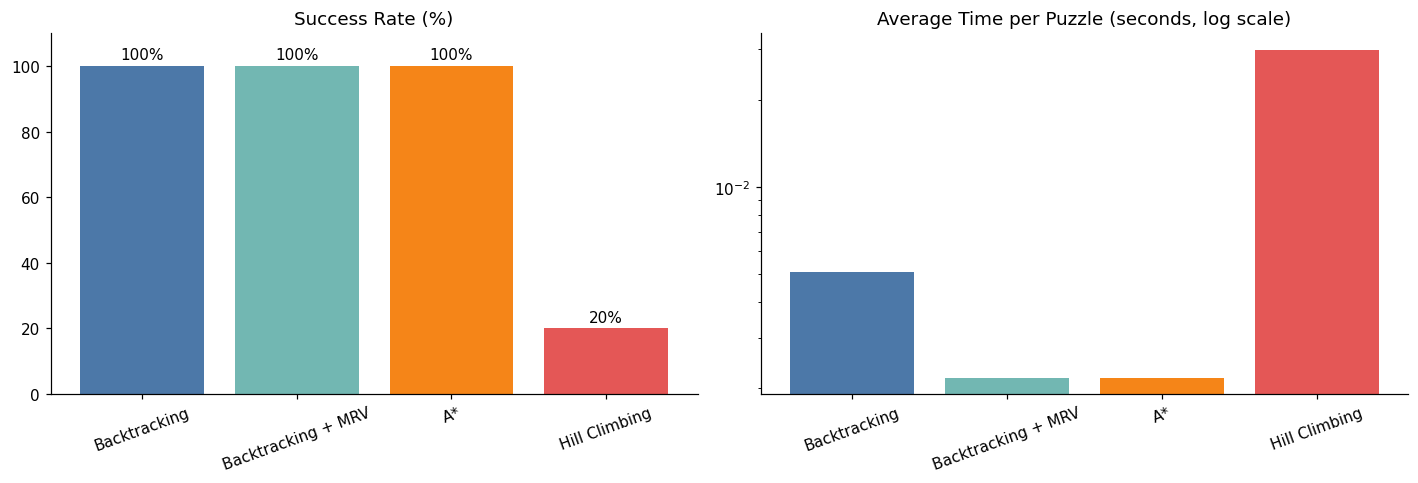

In [35]:
colors=['#4C78A8','#72B7B2','#F58518','#E45756']
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
ax[0].bar(summary.index,summary['success_rate'],color=colors)
ax[0].set_title('Success Rate (%)')
ax[0].set_ylim(0,110)
for i,v in enumerate(summary['success_rate']):
    ax[0].text(i,v+2,f'{v:.0f}%',ha='center')
ax[1].bar(summary.index,summary['mean_time'],color=colors)
ax[1].set_yscale('log')
ax[1].set_title('Average Time per Puzzle (seconds, log scale)')
for a in ax:
    a.tick_params(axis='x',rotation=20)
plt.tight_layout()
plt.show()

## 8. Search effort and time spread
Left: average number of states each algorithm had to generate or evaluate. Right: how much the running time varies from puzzle to puzzle. A short box means the algorithm is predictable.

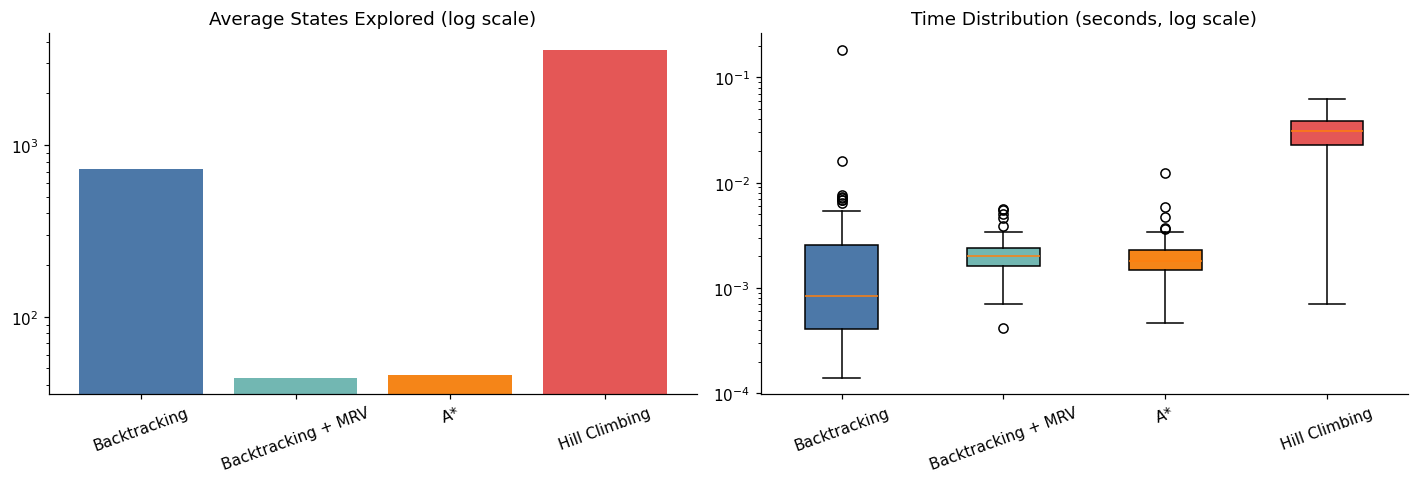

In [36]:
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
ax[0].bar(summary.index,summary['mean_nodes'],color=colors)
ax[0].set_yscale('log')
ax[0].set_title('Average States Explored (log scale)')
ax[0].tick_params(axis='x',rotation=20)
data=[results[results['algorithm']==a]['time'] for a in summary.index]
bp=ax[1].boxplot(data,patch_artist=True)
for patch,c in zip(bp['boxes'],colors):
    patch.set_facecolor(c)
ax[1].set_xticklabels(summary.index,rotation=20)
ax[1].set_yscale('log')
ax[1].set_title('Time Distribution (seconds, log scale)')
plt.tight_layout()
plt.show()

## 9. Effect of difficulty
Puzzles with more blanks are harder. These charts show how each algorithm copes as difficulty goes up.

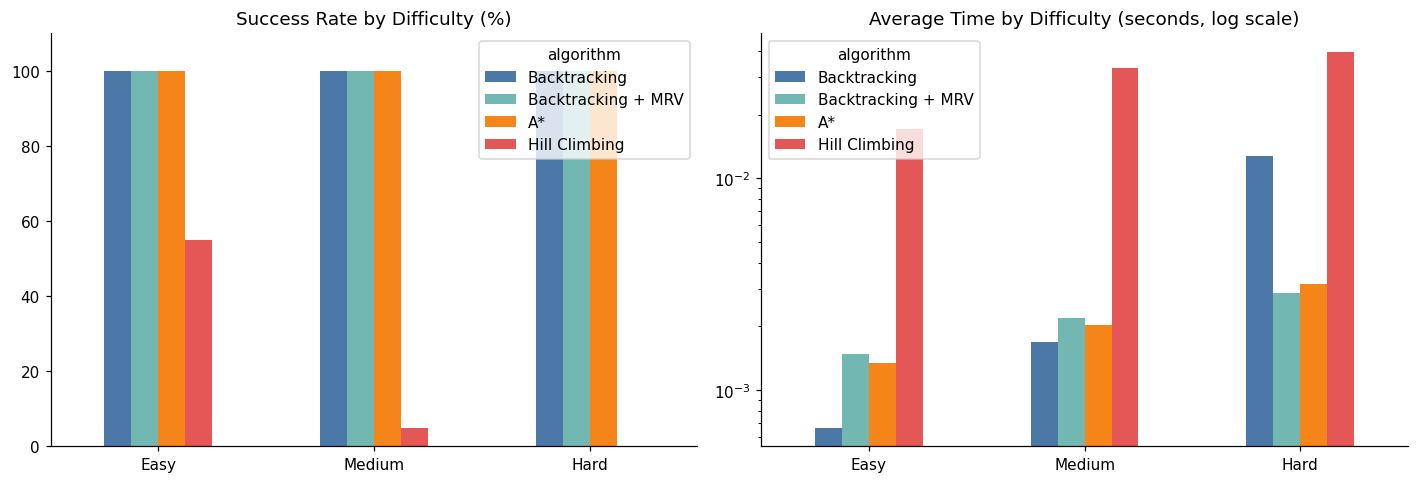

In [37]:
order=['Easy','Medium','Hard']
success=results.pivot_table(index='level',columns='algorithm',values='solved',aggfunc='mean').reindex(order)[list(algorithms)]*100
avg_time=results.pivot_table(index='level',columns='algorithm',values='time',aggfunc='mean').reindex(order)[list(algorithms)]
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
success.plot(kind='bar',ax=ax[0],color=colors,rot=0)
ax[0].set_title('Success Rate by Difficulty (%)')
ax[0].set_xlabel('')
ax[0].set_ylim(0,110)
avg_time.plot(kind='bar',ax=ax[1],color=colors,rot=0,logy=True)
ax[1].set_title('Average Time by Difficulty (seconds, log scale)')
ax[1].set_xlabel('')
plt.tight_layout()
plt.show()

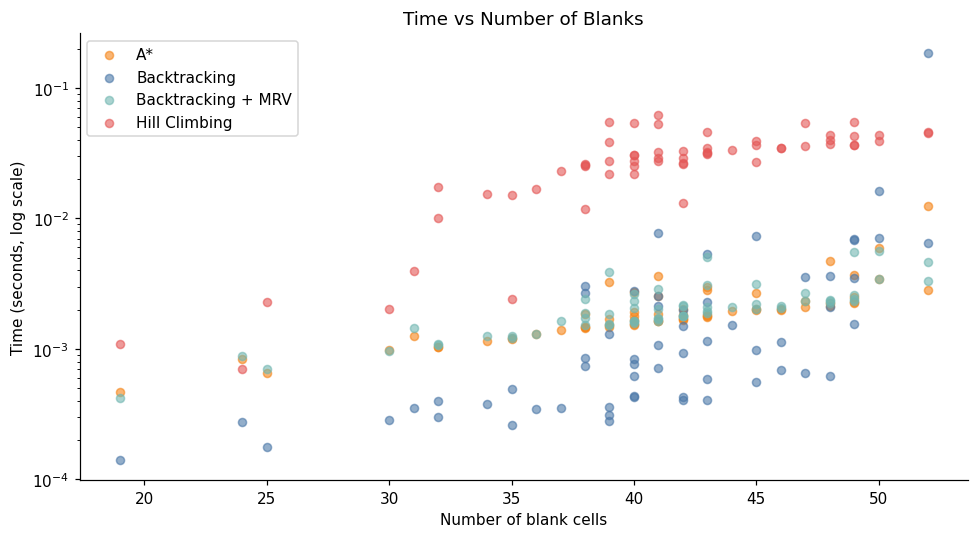

In [38]:
fig,ax=plt.subplots(figsize=(9,5))
for name,grp in results.groupby('algorithm'):
    ax.scatter(grp['blanks'],grp['time'],label=name,alpha=0.6,s=28,color=colors[list(algorithms).index(name)])
ax.set_yscale('log')
ax.set_xlabel('Number of blank cells')
ax.set_ylabel('Time (seconds, log scale)')
ax.set_title('Time vs Number of Blanks')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Picking the best algorithm
Correctness comes first, so algorithms are ranked by success rate. Ties are broken by the lower average time.

In [39]:
ranking=summary.sort_values(['success_rate','mean_time'],ascending=[False,True])
ranking['rank']=range(1,len(ranking)+1)
display(ranking[['rank','success_rate','mean_time','mean_nodes']].round(4))
print('Best algorithm:',ranking.index[0])

,rank,success_rate,mean_time,mean_nodes
algorithm,,,,
A*,1,100.0,0.0022,45.6667
Backtracking + MRV,2,100.0,0.0022,44.2333
Backtracking,3,100.0,0.0051,720.5833
Hill Climbing,4,20.0,0.0300,3591.6667


Best algorithm: A*


## 11. Conclusion
Read these points against the charts above once the notebook has run.

- **Backtracking** solves any valid Sudoku because it is complete, but plain backtracking can waste a lot of time on hard puzzles. Adding **MRV** makes it much more efficient by failing early.
- **A\*** is also complete and guided by a heuristic, so it usually explores few states, but it stores many boards in memory and recomputes the heuristic for each one, which costs time per node.
- **Hill Climbing** is fast per step but incomplete. It gets trapped in local minima where no single swap helps, so its success rate drops as puzzles get harder.

Sudoku is a constraint satisfaction problem, so the algorithm that uses the constraints directly (backtracking with constraint checking and MRV) is the natural fit. The winner printed in section 10 comes from our measured results, so quote the numbers from there on the poster.